<a href="https://colab.research.google.com/github/olopez27CL/Lab01_EDA_Lopez_Omar/blob/main/Laboratorio_2_8_Regresion_Lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Instalar las bibliotecas necesarias
!pip -q install kagglehub pandas numpy matplotlib seaborn scikit-learn statsmodels

# Importar herramientas
from pathlib import Path

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42

print("Preparación completada.")

Preparación completada.


In [ ]:
# Descargar el dataset de Kaggle
ruta_breast = kagglehub.dataset_download(
    "uciml/breast-cancer-wisconsin-data"
)

# Mostrar los archivos descargados
archivos_breast = sorted(Path(ruta_breast).rglob("*"))

print("Archivos disponibles:")
for archivo in archivos_breast:
    if archivo.is_file():
        print(archivo.relative_to(ruta_breast))

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Archivos disponibles:
data.csv


In [ ]:
# Cargar el archivo CSV
df_breast = pd.read_csv(Path(ruta_breast) / "data.csv")

# Mostrar dimensiones y primeras filas
print("Filas y columnas:", df_breast.shape)
display(df_breast.head())

# Revisar los tipos de datos
print("\nInformación del dataset:")
df_breast.info()

# Mostrar las columnas que tienen valores nulos
print("\nColumnas con valores nulos:")
nulos = df_breast.isna().sum()
print(nulos[nulos > 0])

# Revisar filas completamente duplicadas
print("\nFilas duplicadas:", df_breast.duplicated().sum())

Filas y columnas: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  

In [ ]:
# Crear una copia con las mediciones numéricas
breast_limpio = df_breast.drop(
    columns=["id", "diagnosis", "Unnamed: 32"]
).copy()

print("Dimensiones después de la limpieza:", breast_limpio.shape)
print("Valores nulos restantes:", breast_limpio.isna().sum().sum())
print("Filas duplicadas:", breast_limpio.duplicated().sum())

# Resumen de las variables que utilizaremos
variables_breast = ["radius_mean", "perimeter_mean", "area_mean"]

display(breast_limpio[variables_breast].describe())

Dimensiones después de la limpieza: (569, 30)
Valores nulos restantes: 0
Filas duplicadas: 0


,radius_mean,perimeter_mean,area_mean
count,569.000000,569.000000,569.000000
mean,14.127292,91.969033,654.889104
std,3.524049,24.298981,351.914129
min,6.981000,43.790000,143.500000
25%,11.700000,75.170000,420.300000
50%,13.370000,86.240000,551.100000
75%,15.780000,104.100000,782.700000
max,28.110000,188.500000,2501.000000


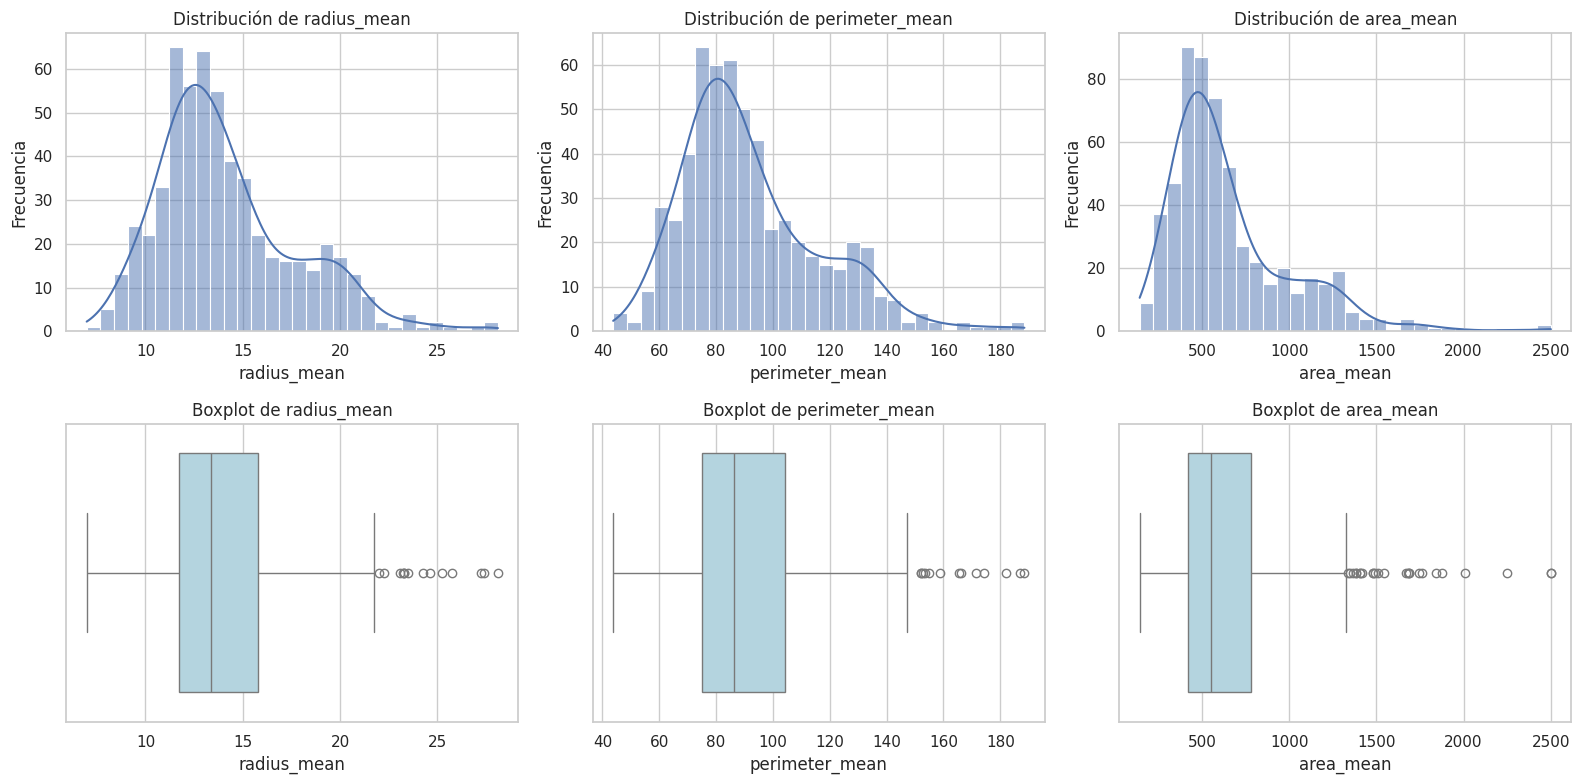

In [ ]:
# Histogramas y boxplots de las variables que vamos a modelar
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, variable in enumerate(variables_breast):
    sns.histplot(
        data=breast_limpio,
        x=variable,
        bins=30,
        kde=True,
        ax=axes[0, i]
    )
    axes[0, i].set_title(f"Distribución de {variable}")
    axes[0, i].set_ylabel("Frecuencia")

    sns.boxplot(
        data=breast_limpio,
        x=variable,
        ax=axes[1, i],
        color="lightblue"
    )
    axes[1, i].set_title(f"Boxplot de {variable}")

plt.tight_layout()
plt.show()

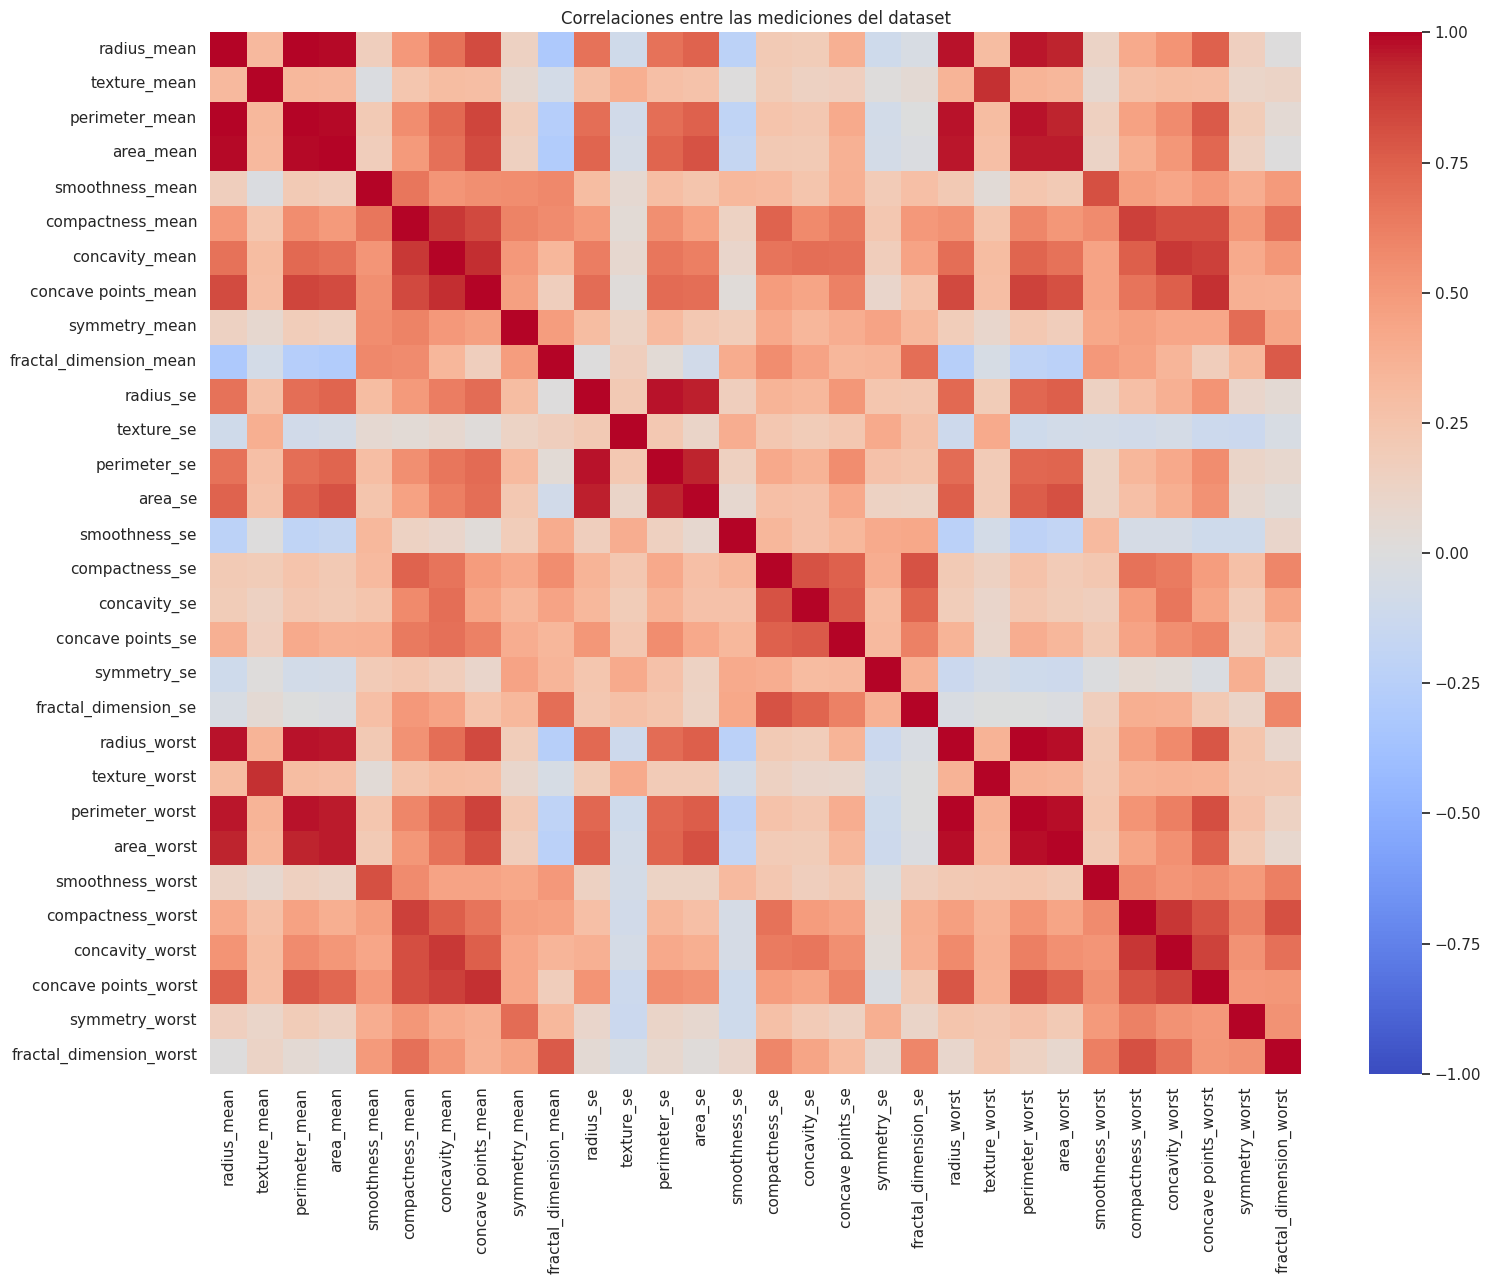

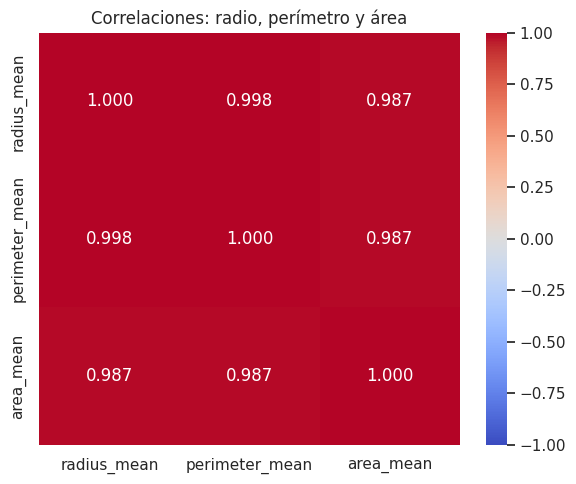

In [ ]:
# Correlaciones entre todas las mediciones
correlaciones_breast = breast_limpio.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(
    correlaciones_breast,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Correlaciones entre las mediciones del dataset")
plt.tight_layout()
plt.show()

# Detalle de las tres variables de nuestros modelos
plt.figure(figsize=(6, 5))
sns.heatmap(
    correlaciones_breast.loc[variables_breast, variables_breast],
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlaciones: radio, perímetro y área")
plt.tight_layout()
plt.show()

In [ ]:
# Separar las mismas filas para ambos modelos
entrenamiento_breast, prueba_breast = train_test_split(
    breast_limpio,
    test_size=0.20,
    random_state=RANDOM_STATE
)

X_train_breast = entrenamiento_breast[["radius_mean"]]
X_test_breast = prueba_breast[["radius_mean"]]

modelos_breast = {}
resultados_breast = []

# Entrenar y evaluar cada modelo
for objetivo in ["perimeter_mean", "area_mean"]:
    y_train = entrenamiento_breast[objetivo]
    y_test = prueba_breast[objetivo]

    modelo = LinearRegression()
    modelo.fit(X_train_breast, y_train)

    predicciones = modelo.predict(X_test_breast)
    modelos_breast[objetivo] = modelo

    resultados_breast.append({
        "Objetivo": objetivo,
        "Pendiente": modelo.coef_[0],
        "Intercepto": modelo.intercept_,
        "R² prueba": r2_score(y_test, predicciones),
        "MAE prueba": mean_absolute_error(y_test, predicciones),
        "RMSE prueba": np.sqrt(
            mean_squared_error(y_test, predicciones)
        )
    })

print("Filas de entrenamiento:", len(entrenamiento_breast))
print("Filas de prueba:", len(prueba_breast))

tabla_breast = pd.DataFrame(resultados_breast)
display(tabla_breast.round(4))

Filas de entrenamiento: 455
Filas de prueba: 114


,Objetivo,Pendiente,Intercepto,R² prueba,MAE prueba,RMSE prueba
0,perimeter_mean,6.8640,-5.0208,0.9957,1.0424,1.5834
1,area_mean,99.0408,-743.8449,0.9812,34.9748,46.5776


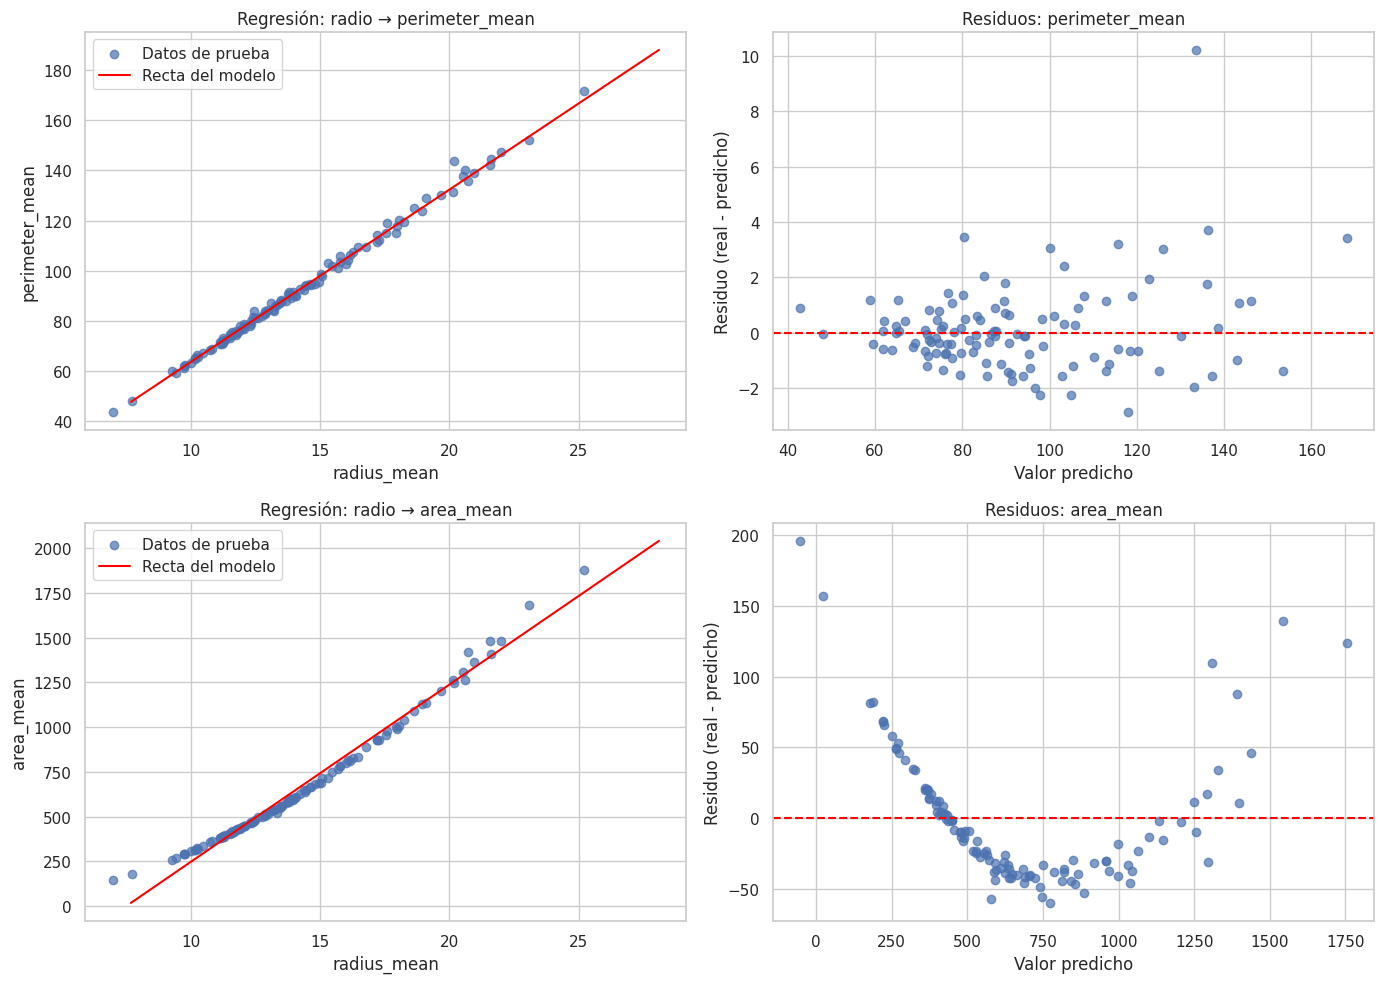

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Radios ordenados para dibujar las rectas entrenadas
radios_linea = pd.DataFrame({
    "radius_mean": np.linspace(
        X_train_breast["radius_mean"].min(),
        X_train_breast["radius_mean"].max(),
        200
    )
})

for i, objetivo in enumerate(["perimeter_mean", "area_mean"]):
    modelo = modelos_breast[objetivo]
    y_test = prueba_breast[objetivo]
    predicciones = modelo.predict(X_test_breast)

    # Residuo = valor real - valor predicho
    residuos = y_test - predicciones

    # Puntos de prueba y recta ajustada solo con entrenamiento
    axes[i, 0].scatter(
        X_test_breast["radius_mean"],
        y_test,
        alpha=0.7,
        label="Datos de prueba"
    )
    axes[i, 0].plot(
        radios_linea["radius_mean"],
        modelo.predict(radios_linea),
        color="red",
        label="Recta del modelo"
    )
    axes[i, 0].set_title(f"Regresión: radio → {objetivo}")
    axes[i, 0].set_xlabel("radius_mean")
    axes[i, 0].set_ylabel(objetivo)
    axes[i, 0].legend()

    # Residuos del conjunto de prueba
    axes[i, 1].scatter(predicciones, residuos, alpha=0.7)
    axes[i, 1].axhline(0, color="red", linestyle="--")
    axes[i, 1].set_title(f"Residuos: {objetivo}")
    axes[i, 1].set_xlabel("Valor predicho")
    axes[i, 1].set_ylabel("Residuo (real - predicho)")

plt.tight_layout()
plt.show()

### Interpretación de los resultados

En el primer modelo se utilizó el radio para predecir el perímetro. La pendiente indica que, cuando el radio aumenta una unidad, el perímetro estimado aumenta aproximadamente 6,86 unidades. El intercepto corresponde a la predicción para un radio de cero, pero no tiene una interpretación práctica porque los datos no incluyen ese valor.

Este modelo obtuvo buenos resultados en prueba. En el gráfico, los puntos se encuentran cerca de la recta y los residuos están repartidos alrededor de cero, aunque presentan mayor dispersión en los valores altos.

En el segundo modelo se utilizó el radio para predecir el área. Su pendiente indica un aumento estimado de 99,04 unidades de área por cada unidad adicional de radio. El intercepto tampoco tiene una interpretación práctica dentro de los datos observados.

Aunque este modelo obtuvo un R² alto, sus residuos forman una curva en U. Esto muestra que la recta comete errores de manera sistemática: estima valores menores a los reales en los extremos y mayores en la parte intermedia.

### ¿Un R² alto es suficiente para concluir que una recta es el modelo adecuado?

No, también es necesario revisar los gráficos de residuos. El modelo de área demuestra que se puede obtener un R² alto y aun así no representar bien la relación con una recta.

En comparación, la recta describe mejor la relación entre el radio y el perímetro. Por eso, para evaluar un modelo debemos considerar tanto sus métricas como el comportamiento de sus errores.